# Grating and prism spectrometers: dispersion, the slit and the Czerny–Turner

A spectrometer sorts light by wavelength in space. A prism or a grating
turns each wavelength into its own direction, a lens or a mirror turns each
direction into its own place on a detector, and an entrance slit sets how
sharp the sorting is. Notebook 100 takes this to the extreme of the echelle,
with resolving powers of $10^5$. This notebook looks at the instrument
found on almost every optical table: a plane grating between two spherical
mirrors, the **Czerny–Turner**, traced ray by ray with
`raytrace.GratingSurface`.

The sections are:

1. prism against grating: angular dispersion and resolving power, and why
   the grating won,
2. the Czerny–Turner traced: the layout, the coma of the off-axis mirrors
   and Shafer's angle that cancels it, astigmatism, the curved image of
   a straight slit and the tilted focal surface,
3. the slit, the instrument function and the detector: resolving the
   sodium D lines, and the trade between light and resolution,
4. grating efficiency from a rigorous (RCWA) calculation of a blazed
   aluminium grating: TE against TM, Wood's anomalies, and when the
   scalar $\mathrm{sinc}^2$ of notebook 100 is good enough,
5. overlapping orders and stray light: order sorting filters and why
   Raman spectrometers are double.

The ray tracing uses `pyoptics.raytrace` (the grating surface and its
sign conventions are described in `GratingSurface`), the spectrometer
builders are in `pyoptics.spectrometers`, the line shapes and instrument
functions in `pyoptics.spectroscopy`, and the rigorous grating in
`pyoptics.litho.rcwa`.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import glasses
from pyoptics import radiometry as rad
from pyoptics import spectrometers as sp
from pyoptics import spectroscopy as spc
from pyoptics import ultrafast as uf
from pyoptics.litho import rcwa

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. Prism against grating

A prism disperses because its index changes with the wavelength. At
minimum deviation, with an apex angle $A$, the exit angle changes as

$$\frac{d\theta}{d\lambda} = \frac{\sin A}{\cos\theta_1'\cos\theta_2}\,\frac{dn}{d\lambda}
  = \frac{b}{D}\,\frac{dn}{d\lambda},$$

with the base $b$ of the prism and the width $D$ of the beam. A grating of
groove spacing $d$ in the order $m$ obeys
$m\lambda = d(\sin\alpha + \sin\beta)$ and disperses by

$$\frac{d\beta}{d\lambda} = \frac{m}{d\cos\beta}.$$

The **resolving power** $R = \lambda/\delta\lambda$ is the smallest
wavelength difference whose diffraction limited images are just
separated (Rayleigh): the angular dispersion times the beam width divided
by the diffraction angle $\lambda/D$. For the prism that is
$R = b\,|dn/d\lambda|$, for the grating $R = mN$ with $N$ the number of
illuminated grooves. Glass data from the catalogue (`glasses`, notebook 61),
prism angles from `ultrafast` (notebook 81):

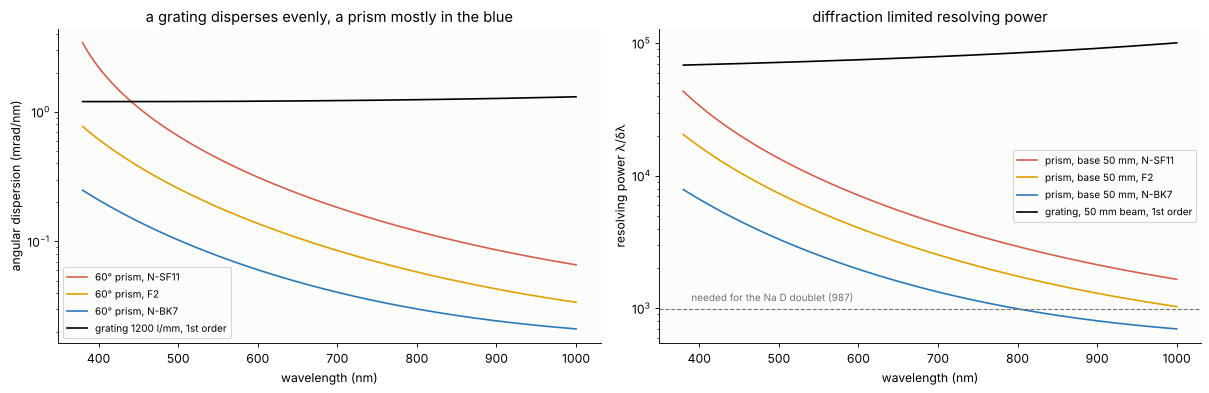

N-SF11  at 589 nm: dn/dλ = -1.51e-04 /nm, R = 7548, dispersion 0.334 mrad/nm (400 nm: 2.200, 800 nm: 0.121)
F2      at 589 nm: dn/dλ = -8.55e-05 /nm, R = 4273, dispersion 0.146 mrad/nm (400 nm: 0.612, 800 nm: 0.058)
N-BK7   at 589 nm: dn/dλ = -4.14e-05 /nm, R = 2068, dispersion 0.063 mrad/nm (400 nm: 0.209, 800 nm: 0.030)
grating at 589 nm: R = 74631, dispersion 1.208 mrad/nm


In [2]:
lam = np.linspace(380, 1000, 400)
apex = np.radians(60.0)
base = 50.0                                    # mm, prism base = 50 mm
G, D_grating = 1200.0, 50.0                    # lines/mm, illuminated width (mm)
prisms = {}
for name, c in (("N-SF11", RED), ("F2", ORANGE), ("N-BK7", BLUE)):
    g = glasses.get(name)
    dn = (g.n(lam + 0.05) - g.n(lam - 0.05))/0.1          # 1/nm
    th = uf.minimum_deviation_incidence(apex, g.n(589.3))
    disp = np.array([uf.prism_dispersion(apex, g.n, l, th) for l in lam])  # rad/nm
    prisms[name] = (c, dn, disp)
# grating: 1200 l/mm at a fixed included angle of 30 degrees
alpha, beta = sp.grating_rotation(lam*1e-6, G, 1, np.radians(30.0))
disp_g = 1*G*1e-6/np.cos(beta)                # rad/nm
R_g = 1*G*D_grating/np.cos(alpha)             # grooves under a 50 mm beam: N = G D/cos(alpha)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for name, (c, dn, disp) in prisms.items():
    ax[0].semilogy(lam, np.abs(disp)*1e3, color=c, label="60° prism, " + name)
    ax[1].semilogy(lam, spc.prism_resolving_power(base*1e6, dn), color=c,
                   label="prism, base 50 mm, " + name)
ax[0].semilogy(lam, disp_g*1e3, color="k", label="grating 1200 l/mm, 1st order")
ax[1].semilogy(lam, R_g, color="k", label="grating, 50 mm beam, 1st order")
ax[1].axhline(589.3/0.597, color=GREY, ls="--", lw=1)
ax[1].text(390, 589.3/0.597*1.15, "needed for the Na D doublet (987)", color=GREY, fontsize=9)
ax[0].set_ylabel("angular dispersion (mrad/nm)")
ax[1].set_ylabel("resolving power λ/δλ")
for a in ax:
    a.set_xlabel("wavelength (nm)")
    a.legend(fontsize=9)
ax[0].set_title("a grating disperses evenly, a prism mostly in the blue")
ax[1].set_title("diffraction limited resolving power")
plt.show()
for name, (c, dn, disp) in prisms.items():
    i = np.argmin(np.abs(lam - 589.3))
    print("{:7s} at 589 nm: dn/dλ = {:.2e} /nm, R = {:.0f}, dispersion {:.3f} mrad/nm (400 nm: {:.3f}, 800 nm: {:.3f})".format(
        name, dn[i], base*1e6*abs(dn[i]), abs(disp[i])*1e3, abs(disp[np.argmin(np.abs(lam - 400))])*1e3,
        abs(disp[np.argmin(np.abs(lam - 800))])*1e3))
i = np.argmin(np.abs(lam - 589.3))
print("grating at 589 nm: R = {:.0f}, dispersion {:.3f} mrad/nm".format(R_g[i], disp_g[i]*1e3))

At the sodium D lines a 50 mm N-SF11 prism resolves $R \approx 7500$, a
dense flint F2 about 4300 and crown glass N-BK7 only about 2100. All of
them are enough to separate the D doublet ($R = 987$), but the prism's
dispersion falls by a factor of 18 from 400 to 800 nm in N-SF11, so its
spectrum is stretched in the blue and squeezed in the red. A 1200 l/mm
grating under the same 50 mm beam has 70 000 to 100 000 grooves at
work and a nearly constant dispersion of about 1.2 mrad/nm, four times
the N-SF11 prism at 589 nm. That, the freedom to choose the dispersion by
the groove density, and the ultraviolet and infrared where no glass is
transparent decided the matter for gratings. Prisms survive where their
weaknesses are virtues: no overlapping orders (section 5), high
transmission, and as the gentle cross-dispersers of echelles (notebook 100).

In practice neither reaches its diffraction limit: the entrance slit
does not let it (section 3).

## 2. The Czerny–Turner, traced

Light from the slit is collimated by a concave mirror, diffracted by a
plane grating and focused by a second concave mirror onto the detector.
Both mirrors are used off axis, at the angles $\varphi_1$ and $\varphi_2$
(half the angle by which they fold the beam). `spectrometers.czerny_turner()`
builds it as a `raytrace.System`: the slit is the object, at the focal
length of the collimator, the collimator is the aperture stop (an f/8
beam here), and coordinate breaks follow the chief ray of the design
wavelength around the folds. The grating is a `GratingSurface` with
1200 lines/mm in the first order, at a fixed angle of 30° between the
beams to and from it. Every other wavelength is traced through the same
hardware with `System.with_wavelength()`.

alpha = 34.98°, beta = 4.98°, phi_1 = 8.00°, Shafer's phi_2 = 4.53°
linear dispersion m f/(d cos β) = 0.1205 mm/nm, i.e. 8.30 nm/mm


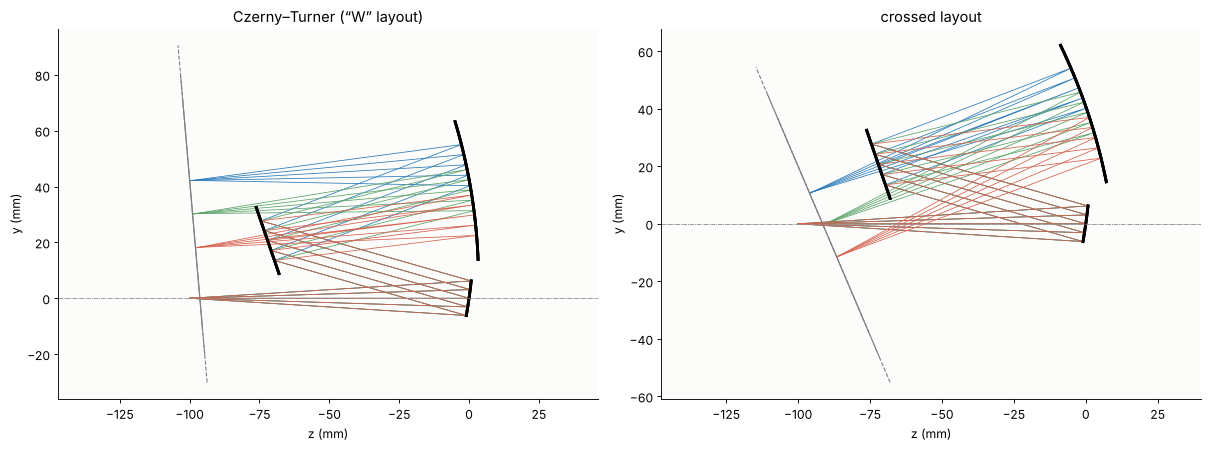

In [3]:
WL0 = 550e-6        # mm
ct = sp.czerny_turner(wavelength=WL0, groove_density=1200, f_collimator=100.0, f_camera=100.0,
                      f_number=8, phi_1=np.radians(8.0), slit_height=5.0)
ct_x = sp.czerny_turner(wavelength=WL0, groove_density=1200, f_collimator=100.0, f_camera=100.0,
                        f_number=8, phi_1=np.radians(8.0), slit_height=5.0, crossed=True)
print("alpha = {:.2f}°, beta = {:.2f}°, phi_1 = {:.2f}°, Shafer's phi_2 = {:.2f}°".format(
    *np.degrees([ct.alpha, ct.beta, ct.phi_1, ct.phi_2])))
print("linear dispersion m f/(d cos β) = {:.4f} mm/nm, i.e. {:.2f} nm/mm".format(
    ct.dispersion, 1/ct.dispersion))

wls = np.array([450, 550, 650])*1e-6
cols = [BLUE, GREEN, RED]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), layout="constrained")
for a, c, title in ((ax[0], ct, "Czerny–Turner (“W” layout)"), (ax[1], ct_x, "crossed layout")):
    for wl, col in zip(wls, cols):
        s = c.system.with_wavelength(wl)
        s.draw(a, fields=[(0.0, 0.0)], n_rays=5, colors=[col], lw=0.7)
    a.set_aspect("equal")
    a.set_title(title)
    a.set_xlabel("z (mm)")
    a.set_ylabel("y (mm)")
plt.show()

On the left the classical layout: slit (at $z = -100$ mm, on the axis)
and detector on one side, the two mirrors side by side on the other, the
grating in between. The detector plane (dashed) lies beside the grating.
Blue, green and red leave the grating at different angles and are focused
at different heights on the detector. On the right the camera mirror
folds the other way and the beams cross, a more compact layout.

**Coma.** An off-axis spherical mirror gives coma that grows with the
off-axis angle and with the cube of the beam width, $\propto W^3\sin\varphi/R^2$.
In the W layout the two mirrors are tilted in opposite senses as seen by the
beam, and their coma can cancel. The grating changes the width of the
collimated beam by $\cos\beta/\cos\alpha$ (the anamorphic
magnification), so the camera sees a wider beam than the collimator and
needs a *smaller* angle. Cancelling the two gives **Shafer's condition**

$$\frac{\sin\varphi_2}{\sin\varphi_1} = \left(\frac{R_2}{R_1}\right)^2
  \left(\frac{\cos\varphi_2}{\cos\varphi_1}\right)^3
  \left(\frac{\cos\alpha}{\cos\beta}\right)^3,$$

`spectrometers.shafer_angle()`. The coma is read off the tangential ray
fan: the image height $y(P_y)$ of rays across the pupil, whose quadratic
part is coma.

quadratic fan coefficient at Shafer's angle: 0.55 µm (W), crossed -66.1 µm, equal angles (W) 27.4 µm


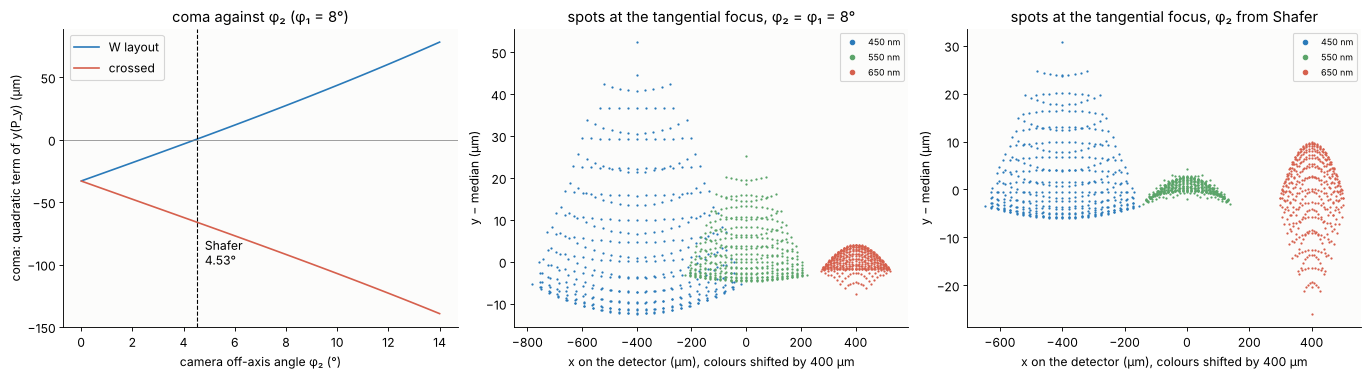

In [4]:
py = np.linspace(-1, 1, 41)
px2, py2 = np.meshgrid(np.linspace(-1, 1, 25), np.linspace(-1, 1, 25))
inside = px2**2 + py2**2 <= 1
px2, py2 = px2[inside], py2[inside]


def fan(system, field=(0.0, 0.0)):
    b = system.trace_pupil(field, 0*py, py)
    return system.to_image_frame(b.points[-1])[:, 1]


def coma_um(system):
    return np.polyfit(py, fan(system), 2)[0]*1e3


def best_focus_y(system, field=(0.0, 0.0)):
    """Shift along the light that minimizes the rms spot size in y (closed form)."""
    b = system.trace_pupil(field, px2, py2)
    P, d = system.to_image_frame(b.points[-1], b.directions[-1])
    ok = np.isfinite(P[:, 1])
    y0, t = P[ok, 1], d[ok, 1]/np.abs(d[ok, 2])
    return -np.cov(y0, t)[0, 1]/np.var(t, ddof=1)


phis = np.radians(np.linspace(0.01, 14, 29))
coma_w = [coma_um(sp.czerny_turner(wavelength=WL0, f_number=8, phi_2=p).system) for p in phis]
coma_c = [coma_um(sp.czerny_turner(wavelength=WL0, f_number=8, phi_2=p, crossed=True).system)
          for p in phis]
print("quadratic fan coefficient at Shafer's angle: {:.2f} µm (W), crossed {:.1f} µm, equal angles (W) {:.1f} µm".format(
    coma_um(ct.system), coma_um(ct_x.system),
    coma_um(sp.czerny_turner(wavelength=WL0, f_number=8, phi_2=ct.phi_1).system)))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
ax[0].plot(np.degrees(phis), coma_w, color=BLUE, label="W layout")
ax[0].plot(np.degrees(phis), coma_c, color=RED, label="crossed")
ax[0].axvline(np.degrees(ct.phi_2), color="k", ls="--", lw=1)
ax[0].text(np.degrees(ct.phi_2) + 0.3, -100, "Shafer\n{:.2f}°".format(np.degrees(ct.phi_2)))
ax[0].axhline(0, color=GREY, lw=0.6)
ax[0].set_xlabel("camera off-axis angle φ₂ (°)")
ax[0].set_ylabel("coma: quadratic term of y(P_y) (µm)")
ax[0].set_title("coma against φ₂ (φ₁ = 8°)")
ax[0].legend()
for a, phi2, title in ((ax[1], ct.phi_1, "φ₂ = φ₁ = 8°"), (ax[2], None, "φ₂ from Shafer")):
    c = sp.czerny_turner(wavelength=WL0, f_number=8, phi_2=phi2)
    s = c.system
    for k, (wl, col) in enumerate(zip(wls, cols)):
        sw = s.with_wavelength(wl)
        b = sw.trace_pupil((0.0, 0.0), px2, py2)
        P, d = sw.to_image_frame(b.points[-1], b.directions[-1])
        z = best_focus_y(sw)                       # each colour at its own tangential focus
        y = P[:, 1] + z*d[:, 1]/np.abs(d[:, 2])
        x = P[:, 0] + z*d[:, 0]/np.abs(d[:, 2])
        a.plot(x*1e3 + (k - 1)*400, (y - np.nanmedian(y))*1e3, ".", ms=2, color=col,
               label="{:.0f} nm".format(wl*1e6))
    a.set_xlabel("x on the detector (µm), colours shifted by 400 µm")
    a.set_ylabel("y − median (µm)")
    a.set_title("spots at the tangential focus, " + title)
    a.legend(fontsize=8, markerscale=4)
plt.show()

With equal angles ($\varphi_2 = \varphi_1 = 8°$) the W layout leaves a
quadratic fan term of 27 µm; at Shafer's angle of 4.53° it drops to
0.6 µm, a factor of 50. The crossed layout cannot cancel coma at all: there
the two mirrors add it (66 µm at the same angle). The spots (each colour
at its own best focus in $y$) show the remaining asymmetry: green, at the
design wavelength, is a narrow arc, while blue and red have coma of
opposite signs, because the angle of diffraction, and with it the
anamorphic factor, changes across the band. Shafer's condition holds for
one wavelength.

The spots are hundreds of µm long in $x$. That is astigmatism, the other
aberration of tilted spherical mirrors.

tangential (y) focus at -1.04 mm, sagittal (x) focus at +1.20 mm: astigmatic difference 2.24 mm
thin mirror estimate f (1/cos φ − cos φ) summed over both mirrors: 2.58 mm


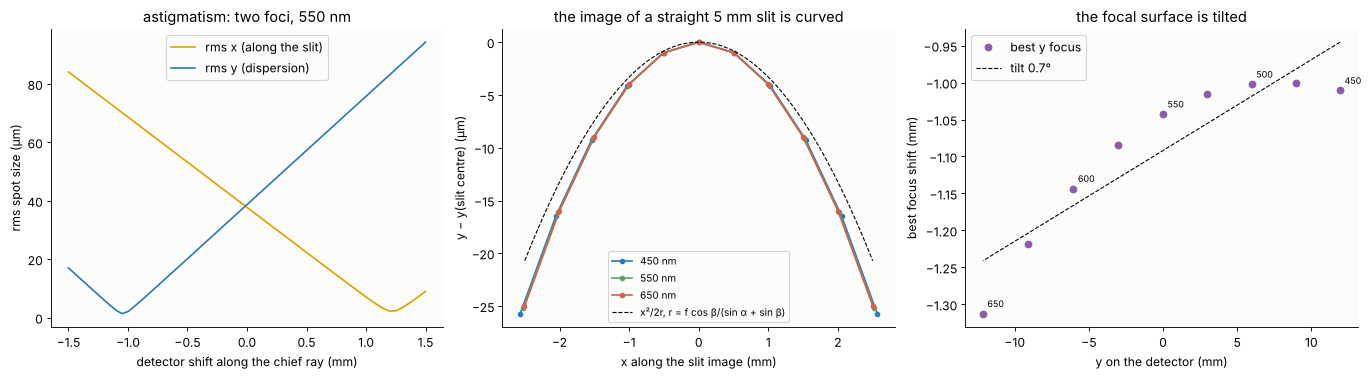

sag of the slit image over ±2.5 mm at 550 nm: 25.2 µm (traced), x²/2r = 20.7 µm
the same layout in the zeroth order (a plane mirror, no dispersion): slit bent by 8.2 µm
detector tilt for a flat field: 0.7°


In [5]:
dz = np.linspace(-1.5, 1.5, 61)


def through_focus(system, field=(0.0, 0.0)):
    b = system.trace_pupil(field, px2, py2)
    P, d = system.to_image_frame(b.points[-1], b.directions[-1])
    # dz along the light (which travels -z of the image frame after an odd
    # number of reflections):
    x = P[:, 0][None] + dz[:, None]*d[:, 0][None]/np.abs(d[:, 2][None])
    y = P[:, 1][None] + dz[:, None]*d[:, 1][None]/np.abs(d[:, 2][None])
    return np.nanstd(x, axis=1), np.nanstd(y, axis=1)


fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
sx, sy = through_focus(ct.system)
ax[0].plot(dz, sx*1e3, color=ORANGE, label="rms x (along the slit)")
ax[0].plot(dz, sy*1e3, color=BLUE, label="rms y (dispersion)")
z_t, z_s = round(best_focus_y(ct.system), 3), dz[np.argmin(sx)]
ax[0].set_xlabel("detector shift along the chief ray (mm)")
ax[0].set_ylabel("rms spot size (µm)")
ax[0].set_title("astigmatism: two foci, 550 nm")
ax[0].legend()
print("tangential (y) focus at {:+.2f} mm, sagittal (x) focus at {:+.2f} mm: astigmatic difference {:.2f} mm".format(
    z_t, z_s, z_s - z_t))
print("thin mirror estimate f (1/cos φ − cos φ) summed over both mirrors: {:.2f} mm".format(
    100*(1/np.cos(ct.phi_1) - np.cos(ct.phi_1)) + 100*(1/np.cos(ct.phi_2) - np.cos(ct.phi_2))))

# the curved image of a straight slit, at the tangential focus
s_t = sp.czerny_turner(wavelength=WL0, f_number=8, detector_shift=z_t).system
xs = np.linspace(-2.5, 2.5, 11)
for wl, col in zip(wls, cols):
    C = sp.centroids(s_t, [(x, 0.0) for x in xs], [wl])[:, 0]
    ax[1].plot(C[:, 0], (C[:, 1] - C[5, 1])*1e3, "o-", ms=4, color=col, label="{:.0f} nm".format(wl*1e6))
xx = np.linspace(-2.5, 2.5, 100)
r_curv = 100*np.cos(ct.beta)/(np.sin(ct.alpha) + np.sin(ct.beta))
ax[1].plot(xx, -xx**2/(2*r_curv)*1e3*np.sign(np.polyfit(C[:, 0], C[:, 1], 2)[0])*-1, "k--", lw=1,
           label="x²/2r, r = f cos β/(sin α + sin β)")
ax[1].set_xlabel("x along the slit image (mm)")
ax[1].set_ylabel("y − y(slit centre) (µm)")
ax[1].set_title("the image of a straight 5 mm slit is curved")
ax[1].legend(fontsize=9)
# focal surface: best y focus against wavelength
wl_scan = np.linspace(450, 650, 9)*1e-6
best, ypos = [], []
for wl in wl_scan:
    sw = ct.system.with_wavelength(wl)
    best.append(best_focus_y(sw))
    b = sw.trace_pupil((0.0, 0.0), 0.0, 0.0)
    ypos.append(sw.to_image_frame(b.points[-1])[0, 1])
best, ypos = np.array(best), np.array(ypos)
slope = np.polyfit(ypos, best, 1)[0]
ax[2].plot(ypos, best, "o", color=PURPLE, label="best y focus")
ax[2].plot(ypos, np.polyval(np.polyfit(ypos, best, 1), ypos), "k--", lw=1,
           label="tilt {:.1f}°".format(np.degrees(np.arctan(slope))))
for wl, yy in zip(wl_scan[::2], ypos[::2]):
    ax[2].annotate("{:.0f}".format(wl*1e6), (yy, best[list(ypos).index(yy)]), textcoords="offset points",
                   xytext=(4, 6), fontsize=8)
ax[2].set_xlabel("y on the detector (mm)")
ax[2].set_ylabel("best focus shift (mm)")
ax[2].set_title("the focal surface is tilted")
ax[2].legend()
plt.show()
print("sag of the slit image over ±2.5 mm at 550 nm: {:.1f} µm (traced), x²/2r = {:.1f} µm".format(
    np.ptp(sp.centroids(s_t, [(x, 0.0) for x in (-2.5, 0.0)], [WL0])[:, 0, 1])*1e3, 2.5**2/(2*r_curv)*1e3))
c0 = sp.czerny_turner(wavelength=WL0, f_number=8, order=0, detector_shift=z_t)   # grating as a mirror
C0 = sp.centroids(c0.system, [(x, 0.0) for x in (-2.5, 0.0)], [WL0])[:, 0, 1]
print("the same layout in the zeroth order (a plane mirror, no dispersion): slit bent by {:.1f} µm".format(
    abs(np.ptp(C0))*1e3))
print("detector tilt for a flat field: {:.1f}°".format(np.degrees(np.arctan(slope))))

**Astigmatism.** A spherical mirror tilted by $\varphi$ focuses the
tangential fan ($y$, the dispersion) at $f\cos\varphi$ and the sagittal
fan ($x$, along the slit) at $f/\cos\varphi$. Traced, the two foci lie
2.24 mm apart; the thin mirror estimate for both mirrors, 2.6 mm, ignores
that the camera sees a collimated beam of a different width. The detector
belongs at the tangential focus (1.04 mm closer to the camera than its
focal length), where the spectral resolution is set. There each point of
the slit is drawn out into a line about 280 µm long *along* the slit.
For a spectrometer with a single long slit this costs nothing; for an
imaging spectrometer, which must keep the points along the slit apart, it
is fatal (notebook 122). Toroidal mirrors, a cylindrical lens or a
divergent beam at the grating cure it.

**The curved slit image.** A point at the height $x$ of the slit sends a
collimated beam that meets the grating slightly out of plane, tilted by
$\gamma = x/f$. The grating equation then holds for the projections on the
plane of dispersion, and the diffracted beam leaves at a slightly larger
angle (conical diffraction). The image of a straight slit becomes an arc of
radius $r = f\cos\beta/(\sin\alpha + \sin\beta)$, here 25 µm of sag over
a 5 mm slit against 20.7 µm from the formula. The rest comes from the
off-axis mirrors themselves, which bend the slit image by 8 µm even when the
grating is used as a mirror in the zeroth order. The curvature is almost the
same for all wavelengths (it depends on $\sin\alpha + \sin\beta = m\lambda/d$,
which changes by 20 % over the band). It is why a tall slit blurs the lines
when the detector columns are summed. Spectrographs either curve the slit
to match, or straighten the image in software.

**The focal surface** of the best tangential focus tilts by about 0.7°
across the detector, as the path from the camera to the focus changes
with the angle. Here the tilt is small, because the camera mirror is
nearly on axis; it is the detector tilt that flat-field spectrographs
build in.

## 3. The slit, the instrument function and the detector

A monochromatic line is imaged as a picture of the entrance slit. Its
width on the detector is the slit width $w$ times the magnification
$(f_\mathrm{cam}/f_\mathrm{coll})\cdot\cos\alpha/\cos\beta$ (the grating
narrows the slit image when $\beta < \alpha$), blurred by the aberrations
and diffraction of the optics and sampled by pixels of width $p$. In
wavelength the slit image has the width

$$\delta\lambda_\mathrm{slit} = \frac{w\cos\alpha}{m\,G\,f_\mathrm{coll}}\qquad(G = 1/d),$$

and a perfect instrument has the trapezoid instrument function of the
slit image convolved with the pixel (`spectroscopy.slit_function()`).
The throughput grows linearly with $w$, the resolution falls with it:
halving the slit halves the light and (as long as the slit dominates)
doubles the resolution. Below, the sodium D lines (588.995 and
589.592 nm, intensities 2 : 1) are traced through the Czerny–Turner: 21
points across the slit width, a pupil grid each, the hits binned in
pixels of 7 µm (pixel width 7 µm, 0.06 nm here).

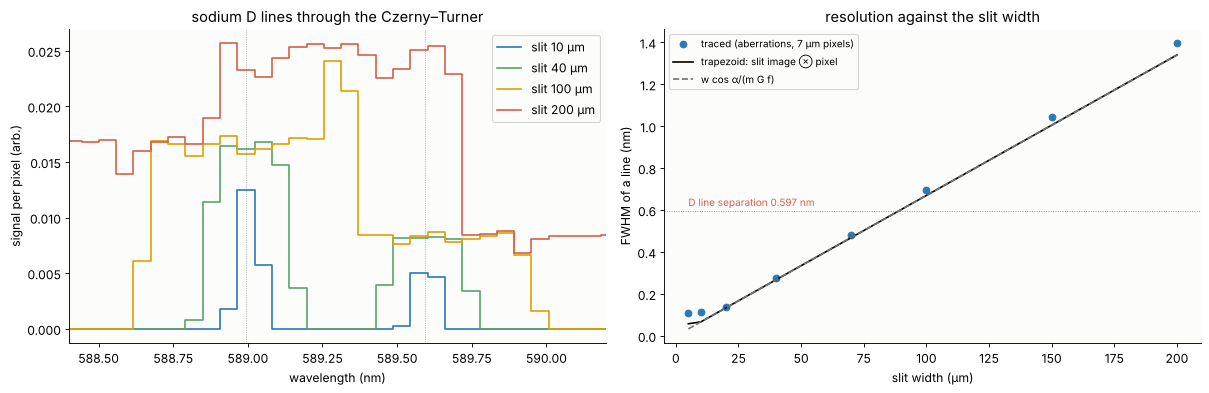

slit image magnification cos α/cos β = 0.809
slit     5 µm: FWHM 0.109 nm traced, 0.058 nm trapezoid, R = 5390
slit    10 µm: FWHM 0.115 nm traced, 0.067 nm trapezoid, R = 5138
slit    20 µm: FWHM 0.139 nm traced, 0.134 nm trapezoid, R = 4235
slit    40 µm: FWHM 0.275 nm traced, 0.268 nm trapezoid, R = 2143
slit    70 µm: FWHM 0.482 nm traced, 0.469 nm trapezoid, R = 1222
slit   100 µm: FWHM 0.695 nm traced, 0.670 nm trapezoid, R = 848
slit   150 µm: FWHM 1.046 nm traced, 1.005 nm trapezoid, R = 564
slit   200 µm: FWHM 1.398 nm traced, 1.340 nm trapezoid, R = 421


In [6]:
NA_D = np.array([588.995, 589.592])*1e-6
NA_W = np.array([2.0, 1.0])
ct_na = sp.czerny_turner(wavelength=589.3e-6, f_number=8, detector_shift=z_t)
s_na = ct_na.system
pix = 0.007                                     # mm
edges = np.arange(-0.6, 0.6 + pix/2, pix) + pix/2
centres = 0.5*(edges[1:] + edges[:-1])
y_ref = s_na.to_image_frame(s_na.trace_pupil((0.0, 0.0), 0.0, 0.0).points[-1])[0, 1]


def detector_spectrum(width, n_slit=21):
    counts = np.zeros(len(centres))
    for wl, w8 in zip(NA_D, NA_W):
        sw = s_na.with_wavelength(wl)
        for ys in np.linspace(-width/2, width/2, n_slit):
            P = sw.to_image_frame(sw.trace_pupil((0.0, ys), px2, py2).points[-1])
            ok = np.isfinite(P[:, 1])
            counts += w8*np.histogram(P[ok, 1] - y_ref, edges)[0]/ok.sum()/n_slit*width
    return counts


widths = [0.010, 0.040, 0.100, 0.200]
spectra = {w: detector_spectrum(w) for w in widths}
disp = ct_na.dispersion
# the sign of the dispersion on the detector: trace two wavelengths
y_lo = s_na.with_wavelength(589.0e-6).to_image_frame(
    s_na.with_wavelength(589.0e-6).trace_pupil((0.0, 0.0), 0.0, 0.0).points[-1])[0, 1]
sgn = np.sign(y_lo - y_ref)*-1
wl_axis = 589.3 + sgn*centres/disp

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for w, c in zip(widths, (BLUE, GREEN, ORANGE, RED)):
    ax[0].plot(wl_axis, spectra[w], color=c, drawstyle="steps-mid", label="slit {:.0f} µm".format(w*1e3))
for l0 in NA_D*1e6:
    ax[0].axvline(l0, color=GREY, lw=0.6, ls=":")
ax[0].set_xlim(588.4, 590.2)
ax[0].set_xlabel("wavelength (nm)")
ax[0].set_ylabel("signal per pixel (arb.)")
ax[0].set_title("sodium D lines through the Czerny–Turner")
ax[0].legend()
# resolution against slit width: traced FWHM of a single line vs the slit formula
w_scan = np.array([0.005, 0.01, 0.02, 0.04, 0.07, 0.1, 0.15, 0.2])
fw_traced, fw_model = [], []
fine = np.arange(-0.4, 0.4, 0.0005)
for w in w_scan:
    sw = s_na.with_wavelength(589.3e-6)
    ys_all = []
    for ys in np.linspace(-w/2, w/2, 21):
        P = sw.to_image_frame(sw.trace_pupil((0.0, ys), px2, py2).points[-1])
        ys_all.append(P[:, 1] - y_ref)
    ys_all = np.concatenate(ys_all)
    h = np.histogram(ys_all[np.isfinite(ys_all)], np.arange(-0.4, 0.4 + pix, pix))[0]
    xc = np.arange(-0.4, 0.4, pix) + pix/2
    fw_traced.append(spc.fwhm(xc, h.astype(float))/disp)
    w_img = w*np.cos(ct_na.alpha)/np.cos(ct_na.beta)
    fw_model.append(spc.fwhm(fine, spc.slit_function(fine, w_img, pix))/disp)
dl_slit = w_scan*np.cos(ct_na.alpha)/(1200*100)*1e6
ax[1].plot(w_scan*1e3, np.array(fw_traced), "o", color=BLUE, label="traced (aberrations, 7 µm pixels)")
ax[1].plot(w_scan*1e3, fw_model, "-", color="k", label="trapezoid: slit image ⊗ pixel")
ax[1].plot(w_scan*1e3, dl_slit, "--", color=GREY, label="w cos α/(m G f)")
ax[1].axhline(0.597, color=RED, lw=0.8, ls=":")
ax[1].text(5, 0.62, "D line separation 0.597 nm", color=RED, fontsize=9)
ax[1].set_xlabel("slit width (µm)")
ax[1].set_ylabel("FWHM of a line (nm)")
ax[1].set_title("resolution against the slit width")
ax[1].legend(fontsize=9)
plt.show()
print("slit image magnification cos α/cos β = {:.3f}".format(np.cos(ct_na.alpha)/np.cos(ct_na.beta)))
for w, ft, fm in zip(w_scan, fw_traced, fw_model):
    print("slit {:5.0f} µm: FWHM {:.3f} nm traced, {:.3f} nm trapezoid, R = {:.0f}".format(w*1e3, ft, fm, 589.3/ft))

At 10 µm the two D lines stand apart, with a resolving power of about
5000. At 40 µm they are still separate, at 100 µm they merge into one
plateau, at 200 µm into one blob, with 20 times the signal of the 10 µm
slit. The traced line widths follow the trapezoid of slit image and
pixel within 5 % down to 20 µm, and the slit formula $w\cos\alpha/(mGf)$
gives 0.068 nm per 10 µm. Below 20 µm the aberrations (the coma left
away from the design wavelength, the spherical aberration of the f/8
mirrors, the slit curvature over the pixel) and the 7 µm pixels set the
width. The diffraction width of the f/8 camera, about 11 µm across the
Airy disk, would add to that in a wave-optical treatment.

The slit limited resolving power $R = mGf/(w\cos\alpha)$ grows with the
size of the instrument for a fixed slit width. For a telescope the slit
must match the image of a star, which grows with the telescope's
diameter, which is how notebook 100 arrives at the $R\phi$ product. The
diffraction limited $R = mN$ of section 1 (75 000) is reached only with
a slit narrower than $\lambda f/D$, about 5 µm here, which wastes most
of the light of any real source.

## 4. Grating efficiency: a blazed aluminium grating in the RCWA

Where the light goes is set by the grating equation; how much of it goes
into an order is set by the groove shape. A ruled grating has sawtooth
grooves whose facets are tilted by the **blaze angle** $\theta_B$: in
the Littrow mount (light sent back on itself) the facets act as small
mirrors facing the beam, and the first order is bright at the blaze
wavelength $\lambda_B = 2d\sin\theta_B$. Scalar theory (as for the
echelle of notebook 100) gives $\eta_1 = \mathrm{sinc}^2(1 - \lambda_B/\lambda)$
times the reflectance of the metal. It is accurate when $d \gg \lambda$,
but a 1200 lines/mm grating has $d = 833$ nm, comparable with the
wavelength, and the two polarizations behave very differently.

The rigorous coupled-wave analysis of `litho.rcwa` (built for masks in
notebook 36 and checked against the FDTD in notebook 62) computes the
sawtooth as a staircase of 24 lamellar layers of aluminium (a Drude model,
$\hbar\omega_p = 15$ eV, $\hbar\gamma = 0.6$ eV, close to tabulated
values except near the 800 nm interband absorption). TE has the electric
field along the grooves, TM across them.

1200 l/mm, blazed at 500 nm: blaze angle 17.46°


300 l/mm, blazed at 500 nm: blaze angle 4.30°
RCWA: 65 s


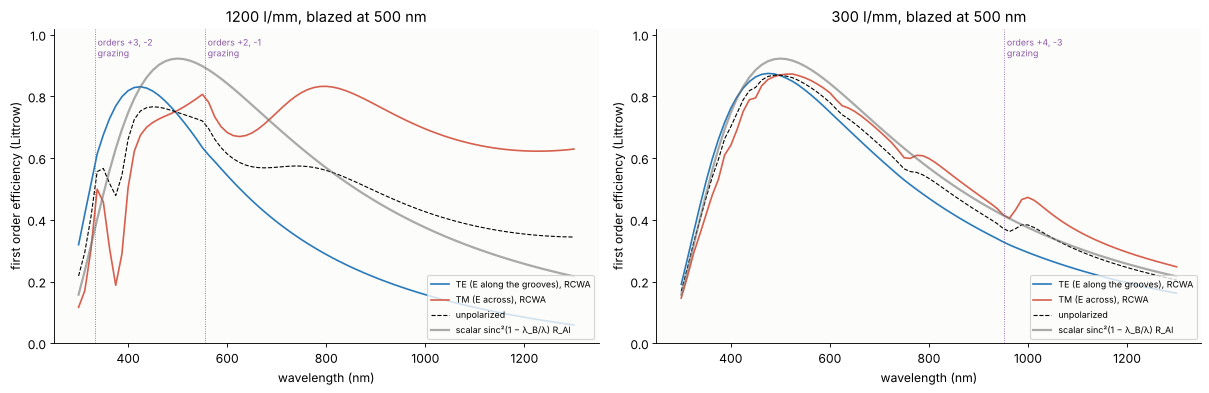

In [7]:
def n_aluminium(lam_um):
    """Drude model of aluminium (hbar omega_p = 15 eV, hbar gamma = 0.6 eV)."""
    E = 1.23984/lam_um
    return np.sqrt(1 - 15.0**2/(E**2 + 1j*0.6*E))


def sawtooth(period, blaze, n_metal, n_layers=24):
    """Staircase of a sawtooth: facets rising with x at the blaze angle."""
    depth = period*np.tan(blaze)
    layers = []
    for i in range(n_layers):
        w = period*(i + 0.5)/n_layers            # metal fraction grows with depth
        layers.append(rcwa.Layer(depth/n_layers, 1.0, [(period - w/2, w, n_metal)]))
    layers.append(rcwa.Layer(0.05, n_metal))
    return layers


def littrow_efficiency(period, blaze, lams, n_orders=25):
    out = {"TE": [], "TM": [], "R": []}
    for l in lams:
        nm = n_aluminium(l)
        sin_a = l/(2*period)
        # light travelling towards +x meets the facets that rise with x;
        # the Littrow order is then m = -1 in the RCWA's convention
        res = rcwa.rcwa(period, sawtooth(period, blaze, nm), l, k_x=sin_a, n_in=1.0, n_out=nm,
                        n_orders=n_orders)
        i1 = int(np.where(res.m == -1)[0][0])
        out["TE"].append(res.efficiencies((0, 1))[0][0, i1])
        out["TM"].append(res.efficiencies((1, 0))[0][0, i1])
        out["R"].append(abs((1 - nm)/(1 + nm))**2)
    return {k: np.array(v) for k, v in out.items()}


lam_um = np.linspace(0.30, 1.30, 81)
cases = [(1/1.2, 0.5, "1200 l/mm, blazed at 500 nm", 20), (1/0.3, 0.5, "300 l/mm, blazed at 500 nm", 45)]
t0 = time.time()
eff = {}
for d_um, lb, label, n_ord in cases:
    blaze = np.arcsin(lb/(2*d_um))
    sel = lam_um < 2*d_um*0.999                  # Littrow exists for λ < 2d
    e = littrow_efficiency(d_um, blaze, lam_um[sel], n_ord)
    eff[label] = (lam_um[sel], e, d_um, lb)
    print("{}: blaze angle {:.2f}°".format(label, np.degrees(blaze)))
print("RCWA: {:.0f} s".format(time.time() - t0))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for a, (label, (l, e, d_um, lb)) in zip(ax, eff.items()):
    scalar = np.sinc(1 - lb/l)**2*e["R"]
    a.plot(l*1e3, e["TE"], color=BLUE, label="TE (E along the grooves), RCWA")
    a.plot(l*1e3, e["TM"], color=RED, label="TM (E across), RCWA")
    a.plot(l*1e3, 0.5*(e["TE"] + e["TM"]), color="k", lw=1, ls="--", label="unpolarized")
    a.plot(l*1e3, scalar, color=GREY, lw=2, alpha=0.6, label="scalar sinc²(1 − λ_B/λ) R_Al")
    # Rayleigh anomalies in Littrow: order m grazes when |sin α + m λ/d| = 1, sin α = λ/2d
    for k in (1.5, 2.5, 3.5):
        lam_r = d_um/k
        if l.min() < lam_r < l.max():
            a.axvline(lam_r*1e3, color=PURPLE, lw=0.8, ls=":")
            a.text(lam_r*1e3 + 5, 0.93, "orders {:+.0f}, {:+.0f}\ngrazing".format(k + 0.5, -(k - 0.5)),
                   color=PURPLE, fontsize=8)
    a.set_ylim(0, 1.02)
    a.set_xlabel("wavelength (nm)")
    a.set_ylabel("first order efficiency (Littrow)")
    a.set_title(label)
    a.legend(fontsize=8, loc="lower right")
plt.show()

For the coarse 300 l/mm grating ($d = 3.3$ µm, a blaze angle of 4.3°)
scalar theory works: both polarizations peak near 500 nm at 87 %, a few
per cent below scalar theory's 92 % (the aluminium reflectance, minus the
shadowing of the risers), and fall off together on both sides. The small
kink near 950 nm is a Rayleigh (Wood) anomaly: an order turns grazing,
and its energy is redistributed. For the 1200 l/mm grating
($d = 833$ nm, $\theta_B = 17.5°$) the two polarizations part ways. TE peaks
at 83 % near 420 nm and falls steeply in the red, TM stays above 60 % out
to 1300 nm. At 555 nm, where the orders +2 and −1 graze in Littrow, TM
shows Wood's anomaly as a sharp step, the same feature that puzzled Wood in
1902 and that Rayleigh explained. Near 370 nm TM shows a deep dip, most likely a surface
plasmon of the aluminium excited by an evanescent order. The unpolarized
efficiency of the fine grating peaks below 80 % and is flat over a wide band.

The practical rules from these curves (and from the manufacturers' catalogues)
are that a grating is efficient from about $2\lambda_B/3$ to $2\lambda_B$
when $\lambda/d < 0.2$, that the efficiency depends strongly on polarization when
$\lambda/d > 0.5$, which spectrometers that measure polarized light must
calibrate, and that anomalies show up as sharp features in a lamp spectrum
which are no property of the lamp.

## 5. Overlapping orders and stray light

**Orders.** The grating equation only knows $m\lambda$: at the place
where the first order of 800 nm lands, the second order of 400 nm lands
too, and the third order of 267 nm. A spectrometer that covers more than
an octave must block the higher orders with **order sorting filters**,
usually a long-pass glass filter over the red half of the detector. Below,
a xenon arc lamp (roughly a 6000 K black body, `radiometry.planck_radiance()`)
is seen by a silicon detector from 300 to 1050 nm through a 1200 l/mm
grating blazed at 750 nm for the near infrared (scalar efficiencies,
$\eta_m = \mathrm{sinc}^2(m - \lambda_B/\lambda)$, enough for the order
bookkeeping). Its second order is blazed at 375 nm, just where the lamp is
bright.

at 900 nm without filter the 2nd order (450 nm) adds 45 % to the true signal


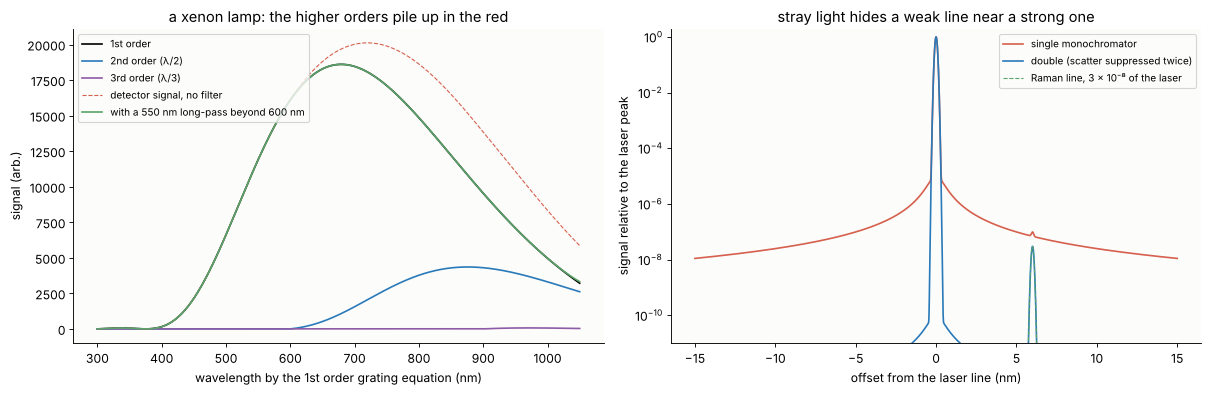

In [8]:
lam_det = np.linspace(300, 1050, 751)                       # wavelength assigned by the 1st order
qe = np.clip(np.sin(np.pi*(lam_det - 300)/900), 0, None)*0.8 # a rough silicon QE curve, 300 - 1200 nm


def qe_at(l):
    return np.interp(l, lam_det, qe, left=0.0, right=0.0)


def lamp(l):
    return rad.planck_radiance(l, 6000.0)


lb = 750.0                                                   # a grating blazed for the near infrared
first = lamp(lam_det)*np.sinc(1 - lb/lam_det)**2*qe_at(lam_det)
l2 = lam_det/2
second = lamp(l2)*np.sinc(2 - lb/l2)**2*qe_at(l2)*0.5   # per nm of the 2nd order: dλ/dy halves
l3 = lam_det/3
third = lamp(l3)*np.sinc(3 - lb/l3)**2*qe_at(l3)/3
lp = 1/(1 + np.exp(-(lam_det - 550)/8))                  # a long-pass filter, cut-on 550 nm
filt = np.where(lam_det > 600, lp, 1.0)                  # mounted over the part beyond 600 nm
ftr = lambda l: np.where(lam_det > 600, 1/(1 + np.exp(-(l - 550)/8)), 1.0)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
ax[0].plot(lam_det, first, color="k", label="1st order")
ax[0].plot(lam_det, second, color=BLUE, label="2nd order (λ/2)")
ax[0].plot(lam_det, third, color=PURPLE, label="3rd order (λ/3)")
ax[0].plot(lam_det, first + second + third, color=RED, lw=1, ls="--", label="detector signal, no filter")
ax[0].plot(lam_det, first*ftr(lam_det) + second*ftr(l2) + third*ftr(l3), color=GREEN, lw=1.5,
           label="with a 550 nm long-pass beyond 600 nm")
ax[0].set_xlabel("wavelength by the 1st order grating equation (nm)")
ax[0].set_ylabel("signal (arb.)")
ax[0].set_title("a xenon lamp: the higher orders pile up in the red")
ax[0].legend(fontsize=9)
i900 = np.argmin(np.abs(lam_det - 900))
print("at 900 nm without filter the 2nd order (450 nm) adds {:.0f} % to the true signal".format(
    100*second[i900]/first[i900]))

# stray light: a laser line and weak Raman lines, single against double monochromator
nu_off = np.linspace(-15, 15, 3001)            # nm from the laser
core = spc.voigt(nu_off, 0.0, 0.15, 0.0)
core /= core.max()
wing = 1e-5/(1 + (nu_off/0.5)**2)              # scatter of the grating and the optics, Lorentzian wings
raman = 3e-8*spc.voigt(nu_off, 6.0, 0.15, 0.0)/spc.voigt(0.0, 0.0, 0.15, 0.0)
single = core + wing + raman
double = core + 1e-5*wing + raman      # the second stage scatters the wing again
ax[1].semilogy(nu_off, single, color=RED, label="single monochromator")
ax[1].semilogy(nu_off, double, color=BLUE, label="double (scatter suppressed twice)")
ax[1].semilogy(nu_off, raman + 1e-14, color=GREEN, lw=1, ls="--", label="Raman line, 3 × 10⁻⁸ of the laser")
ax[1].set_ylim(1e-11, 2)
ax[1].set_xlabel("offset from the laser line (nm)")
ax[1].set_ylabel("signal relative to the laser peak")
ax[1].set_title("stray light hides a weak line near a strong one")
ax[1].legend(fontsize=9)
plt.show()

**Orders.** At 900 nm the second order of 450 nm adds 45 % to the true
signal of the xenon lamp. Without a filter, the red half of the spectrum is
wrong, and spectral lines from 350 to 525 nm reappear as ghosts from 700 to
1050 nm. A long-pass filter with its edge at 550 nm, mounted over the part
of the detector beyond 600 nm, removes the second and third orders while
leaving the first order untouched. The filter edge must lie below the
shortest wavelength it covers and above half the longest.

**Stray light.** A grating scatters a little light into all directions:
roughness of the grooves, ruling errors (ghost lines) and dust give wings
around a strong line. With wings of $10^{-5}$ of the peak at 0.5 nm, a
Raman line 6 nm away at $3\times10^{-8}$ of the laser is barely visible
on the wing of a single monochromator. A second stage that disperses the
light again sees the wing only where the first stage has put it, and
scatters it once more, so the stray light drops to the square of a single
stage. Raman spectrometers that look close to the laser line use double or
triple monochromators, or a notch filter in front of a single stage.

## Summary

- **Prism and grating:** $R = b\,|dn/d\lambda|$ against $R = mN$. A
  50 mm N-SF11 prism resolves about 7500 at 589 nm, a 1200 l/mm grating
  under the same beam 75 000 with a nearly constant dispersion, and gratings
  work beyond the transparency of glass.
- **The Czerny–Turner,** traced with `raytrace.GratingSurface` and built by
  `spectrometers.czerny_turner()`: 0.12 mm/nm at f = 100 mm and 1200 l/mm.
  Coma of the off-axis mirrors cancels at Shafer's angle (27 µm → 0.6 µm
  at 550 nm, in the W layout only, exact at one wavelength). Astigmatism
  separates the foci by 2.2 mm and stretches each slit point along the
  slit. The image of a straight slit is curved with
  $r = f\cos\beta/(\sin\alpha + \sin\beta)$, and the focal surface is
  tilted.
- **Slit:** the line width is the slit image ($w\cos\alpha/(mGf)$, 0.068 nm
  per 10 µm here) convolved with pixel and aberrations; the D lines
  (0.6 nm) separate up to a slit of about 70 µm. Light and resolution
  trade linearly.
- **Efficiency:** scalar $\mathrm{sinc}^2$ for $d \gg \lambda$. At
  1200 l/mm the RCWA shows TE and TM parting in the red, Wood's anomaly
  where an order grazes, and a plasmon dip.
- **Orders and stray light:** order sorting filters for spectra that
  span more than an octave (45 % second order at 900 nm without), double
  monochromators to square the stray light around strong lines.

In [9]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 69 s


## References

- M. Czerny and A. F. Turner, "Über den Astigmatismus bei
  Spiegelspektrometern", Z. Phys. 61, 792–797 (1930).
- A. B. Shafer, L. R. Megill and L. Droppleman, "Optimization of the
  Czerny–Turner spectrometer", J. Opt. Soc. Am. 54, 879–887 (1964).
- C. Palmer, *Diffraction Grating Handbook*, 8th ed., MKS Newport (2020).
- E. G. Loewen and E. Popov, *Diffraction Gratings and Applications*,
  Marcel Dekker (1997).
- J. F. James, *Spectrograph Design Fundamentals*, Cambridge University
  Press (2007).
- R. W. Wood, "On a remarkable case of uneven distribution of light in a
  diffraction grating spectrum", Phil. Mag. 4, 396–402 (1902); Lord
  Rayleigh, "On the dynamical theory of gratings", Proc. R. Soc. A 79,
  399–416 (1907).
- M. G. Moharam, E. B. Grann, D. A. Pommet and T. K. Gaylord,
  "Formulation for stable and efficient implementation of the rigorous
  coupled-wave analysis of binary gratings", J. Opt. Soc. Am. A 12,
  1068–1076 (1995).
- A. D. Rakić, A. B. Djurišić, J. M. Elazar and M. L. Majewski,
  "Optical properties of metallic films for vertical-cavity
  optoelectronic devices", Appl. Opt. 37, 5271–5283 (1998).